# Lattice surgery: a CNOT on surface-code patches

> **In short.**
> * **The setting.** Lattice surgery computes with surface-code patches by changing which checks are measured. A *split* cuts one patch into two by measuring the checks of a new boundary; a *merge* joins two patches by measuring the checks across the seam between them. Kissinger (*Phase-free ZX diagrams are CSS codes*, Section 7.1) shows on 3×3 patches that a split is a **Z-split** (a green spider with one leg in and two out), a merge is an **X-merge** (a red spider with two legs in and one out, after measuring $XX$), and a Z-split followed by an X-merge is a **CNOT**.
> * **The program.** 42 qubits on a chip: a control patch of 6×3 data qubits, a target patch of 3×3, an ancilla for every X check, and two input qubits. Four stages: encode the control, encode the target, split the control in two (one $XX$ check), and merge its lower half with the target (two X checks across the seam).
> * **What the tool finds**, from the gates alone. The codes after every stage. Read as one code, the two halves of the split control still share a stabilizer, so the split does nothing yet and the merge does the CNOT. Read as separate patches, as Kissinger does, the split is a Z-split and the merge an $XX$ measurement. Levelled up, split and merge are one block: a CNOT, up to a Pauli frame that the outcomes decide.

The derivation of Kissinger's Section 7.1 on these patches, level by level, is in [LatticeSurgeryStepByStep.ipynb](LatticeSurgeryStepByStep.ipynb).

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from pyzx.circuit import Circuit
from pyzx.circuit.gates import CNOT, HAD, Measurement, Reset
from zxqec.qprogram import QProgram
from zxqec.codes import surface_code_checks, logical_action
from zxqec.spacetime import Topology, draw_program_3d

## 1. The chip and the program

The data qubits sit on a grid of rows and columns: the control patch on rows 0–5 and columns 0–2 (qubits 0–17, row by row), the target patch on rows 3–5 and columns 3–5 (qubits 18–26). The two inputs are qubits 27 (control) and 28 (target).

The checks come from `surface_code_checks(rows, cols, parity)`: the rotated surface code on a patch of that size, X checks on the top and bottom edges, Z checks on the left and right edges. Which faces are X and which are Z alternates like a checkerboard over the whole chip, so a patch that starts at an odd position (row + column odd) has the other checkerboard (`parity=1`): the merged patch, which starts at row 3, column 0. The target starts at row 3, column 3, and has the usual one.

* **Encoding a patch** (as in the fold-transversal Hadamard): its data qubits start in $|0\rangle$, so its Z checks already hold; the input is fanned out by CNOTs onto the patch's logical $X$ (a column) and measured in the X basis; then every X check of the patch is measured with an ancilla of its own.
* **The Z-split**: the $XX$ check on qubits (2, 0) and (2, 1), the bottom edge of the upper half. It is measured by the ancilla of the control's X check on (2, 0), (2, 1), (3, 0), (3, 1), which sits at the same place; that ancilla is reset first.
* **The X-merge**: the X checks of the merged 3×6 patch (rows 3–5, columns 0–5) that cross the seam between columns 2 and 3: one of weight 2 and one of weight 4.

X checks: control 7  target 4  seam [[11, 18], [14, 21, 17, 24]]
qubits: 42


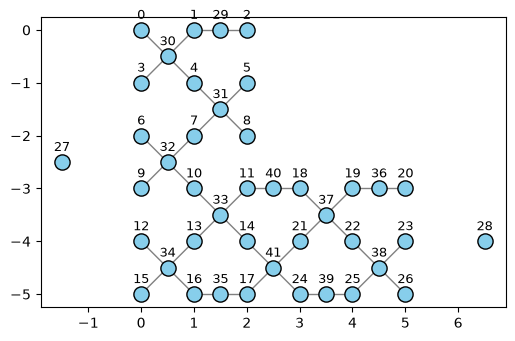

In [2]:
CONTROL = [(r, c) for r in range(6) for c in range(3)]
TARGET = [(r, c) for r in range(3, 6) for c in range(3, 6)]
DATA = {rc: q for q, rc in enumerate(CONTROL + TARGET)}         # (row, column) -> qubit
C_IN, T_IN = 27, 28
control_x = [[DATA[(i // 3, i % 3)] for i in np.flatnonzero(row)] for row in surface_code_checks(6, 3)[0]]
target_x = [[DATA[(3 + i // 3, 3 + i % 3)] for i in np.flatnonzero(row)] for row in surface_code_checks(3)[0]]
merged_x = [[DATA[(3 + i // 6, i % 6)] for i in np.flatnonzero(row)] for row in surface_code_checks(3, 6, parity=1)[0]]
seam_x = [f for f in merged_x if any(q < 18 for q in f) and any(q >= 18 for q in f)]
split_xx = [DATA[(2, 0)], DATA[(2, 1)]]
ANCILLA = {tuple(f): 29 + k for k, f in enumerate(control_x + target_x + seam_x)}
SEAM = ANCILLA[next(tuple(f) for f in control_x if set(split_xx) < set(f))]
N = 29 + len(ANCILLA)
print("X checks: control", len(control_x), " target", len(target_x), " seam", seam_x)
print("qubits:", N)

# the chip: data qubit (row, column) at (column, -row), each ancilla in the middle of its check
where = {q: (c, -r) for (r, c), q in DATA.items()}
chip = Topology()
for q, xy in where.items():
    chip.add_node(q, xy)
chip.add_node(C_IN, (-1.5, -2.5))
chip.add_node(T_IN, (6.5, -4.0))
for f, a in ANCILLA.items():
    chip.add_node(a, tuple(np.mean([where[q] for q in f], axis=0)))
    for q in f:
        chip.add_edge(a, q)
chip.draw(labels=True, node_size=120);

The chip: data qubits on the grid, every ancilla in the middle of the qubits it checks (joined to them), the two inputs on the left and right.

In [3]:
BITS = 2 + len(ANCILLA) + 1
program = QProgram(N, bits=BITS, topology=chip, initial_states={q: '0' for q in range(N) if q not in (C_IN, T_IN)})
bit = iter(range(BITS))     # the results c[0], c[1], ... in the order they are measured
# an X check: its ancilla in |+> (H on |0>), a CNOT onto each of its qubits, back to the Z basis, measured
stages = [
    ('encode control', [CNOT(C_IN, DATA[(r, 0)]) for r in range(6)] + [HAD(C_IN), Measurement(C_IN, next(bit))]
                       + [g for f in control_x for a in [ANCILLA[tuple(f)]]
                          for g in [HAD(a)] + [CNOT(a, q) for q in f] + [HAD(a), Measurement(a, next(bit))]]),
    ('encode target', [CNOT(T_IN, DATA[(r, 3)]) for r in range(3, 6)] + [HAD(T_IN), Measurement(T_IN, next(bit))]
                      + [g for f in target_x for a in [ANCILLA[tuple(f)]]
                         for g in [HAD(a)] + [CNOT(a, q) for q in f] + [HAD(a), Measurement(a, next(bit))]]),
    ('Z-split', [Reset(SEAM), HAD(SEAM)] + [CNOT(SEAM, q) for q in split_xx] + [HAD(SEAM), Measurement(SEAM, next(bit))]),
    ('X-merge', [g for f in seam_x for a in [ANCILLA[tuple(f)]]
                 for g in [HAD(a)] + [CNOT(a, q) for q in f] + [HAD(a), Measurement(a, next(bit))]]),
]
for name, gates in stages:
    c = Circuit(N, bit_amount=BITS)
    for gate in gates:
        c.add_gate(gate)
    program.add_circuit(c, name=name)
print(program.num_stages, "stages,", program.quantum_graph().num_vertices(), "spiders")

4 stages, 238 spiders


## 2. Question 1: the code after every stage

In [4]:
for s in range(program.num_stages):
    print("after stage {} ({}):".format(s, program.stage(s).name))
    for block in program.code_at(s).blocks():
        print("   ", block.describe().splitlines()[0])

after stage 0 (encode control):
    [[18, 1, 3]] CSS code on qubits 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17
    [[1, 1, 1]] CSS code on qubits 28
after stage 1 (encode target):


    [[18, 1, 3]] CSS code on qubits 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17
    [[9, 1, 3]] CSS code on qubits 18, 19, 20, 21, 22, 23, 24, 25, 26
after stage 2 (Z-split):


    [[18, 1, 3]] CSS code on qubits 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17
    [[9, 1, 3]] CSS code on qubits 18, 19, 20, 21, 22, 23, 24, 25, 26
after stage 3 (X-merge):


    [[9, 1, 3]] CSS code on qubits 0, 1, 2, 3, 4, 5, 6, 7, 8
    [[18, 1, 3]] CSS code on qubits 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26


* After encoding, the control is a **[[18,1,3]]** code, the 6×3 patch, and the target input is still a bare qubit; then the target is a **[[9,1,3]]** code.
* After the split, the control is **still [[18,1,3]]**: one code, not two.
* After the merge, the upper half of the control is a [[9,1,3]] code of its own, and the lower half and the target are one **[[18,1,3]]** code, the merged 3×6 patch.

Why the split does not split the code: the tool reads the code of what the program can hold, and after the split the control's two halves still hold *one* logical qubit together. Its stabilizers include $Z_L \otimes Z_L$, the product of the two halves' logical $Z$ (their top rows, qubits 0–2 and 9–11):

In [5]:
after_split = program.code_at(2)
zz = ''.join('Z' if q in (0, 1, 2, 9, 10, 11) else 'I' for q in range(27))
print(after_split.data().blocks()[0])
print("Z_L x Z_L of the two halves is a stabilizer:", after_split.data().contains(zz))

[[18, 1, 3]] CSS code on qubits 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17
    stabilizer (-1)^(c[1])IXXIIIIIIIIIIIIIII
    stabilizer (-1)^(c[13])IIIIIIXXIIIIIIIIII
    stabilizer (-1)^(c[7])IIIIIIIIIIIIIIIIXX
    stabilizer (-1)^(c[13] + c[4])IIIIIIIIIXXIIIIIII
    stabilizer (-1)^(c[2])XXIXXIIIIIIIIIIIII
    stabilizer (-1)^(c[3])IIIIXXIXXIIIIIIIII
    stabilizer (-1)^(c[5])IIIIIIIIIIXXIXXIII
    stabilizer (-1)^(c[6])IIIIIIIIIIIIXXIXXI
    stabilizer +ZIIZIIIIIIIIIIIIII
    stabilizer +IIIIIZIIZIIIIIIIII
    stabilizer +IIIIIIIIIIIZIIZIII
    stabilizer +IIIIIIIIIIIIZIIZII
    stabilizer +ZIIIZIZZIIIIIIIIII
    stabilizer +IZZIZZIIIIIIIIIIII
    stabilizer +IIIIIIIIIZZIZZIIII
    stabilizer +IIIIIIIIIIIZIZIIZZ
    stabilizer +ZZZIIIIIIZZZIIIIII
    logical X XIIXIIXIIXIIXIIXII   logical Z ZZZIIIIIIIIIIIIIII


Z_L x Z_L of the two halves is a stabilizer: True


This is the "same code block" view: as long as nothing acts on one half alone, the two halves are one code. Kissinger reads them as **separate patches** instead, an encoder $E \otimes E$ for each. `separated(parts)` gives that code: only the stabilizers that act within one part, with their signs. It drops $Z_L \otimes Z_L$, so the two halves become two [[9,1,3]] codes, each with a logical qubit of its own:

In [6]:
TOP = [DATA[rc] for rc in CONTROL[:9]]
COPY = [DATA[rc] for rc in CONTROL[9:]]
separate = after_split.separated([TOP, COPY, [q for q in after_split.qubits if q not in TOP + COPY]])
for block in separate.blocks():
    print(block.describe().splitlines()[0])

[[9, 1, 3]] CSS code on qubits 0, 1, 2, 3, 4, 5, 6, 7, 8
[[9, 1, 3]] CSS code on qubits 9, 10, 11, 12, 13, 14, 15, 16, 17
[[9, 1, 3]] CSS code on qubits 18, 19, 20, 21, 22, 23, 24, 25, 26


## 3. Questions 2 and 3, block by block

The first level has one block per stage (`group_stages`; the tool numbers this level 4, one level-up per group). First as the program reads its own codes: the split is the identity on the one logical qubit of the control, and the merge, from that code and the target to the upper half and the merged patch, is the CNOT.

In [7]:
level1 = program.group_stages([(0, 0, 'encode control', 'encoder'), (1, 1, 'encode target', 'encoder'),
                               (2, 2, 'Z-split', None), (3, 3, 'X-merge', None)])
print(program.summary(level1).table())

block             role     code before             code after              logical action  every run?  checks
0 encode control  encoder  [[1,1,1]] + [[1,1,1]]   [[18,1,3]] + [[1,1,1]]  I               yes         ok
1 encode target   encoder  [[18,1,3]] + [[1,1,1]]  [[18,1,3]] + [[9,1,3]]  I               yes         ok
2 Z-split         -        [[18,1,3]] + [[9,1,3]]  [[18,1,3]] + [[9,1,3]]  I               yes         ok
3 X-merge         -        [[18,1,3]] + [[9,1,3]]  [[9,1,3]] + [[18,1,3]]  CNOT(0->1)      yes         ok


Then with the halves read as separate patches, between the codes of Section 2:

In [8]:
split = logical_action(program.block_graph(level1, 2, classical=False), program.code_at(1), separate)
merge = logical_action(program.block_graph(level1, 3, classical=False), separate, program.code_at(3))
print("Z-split:", split.verdict())
print()
print("X-merge:", merge.verdict())

Z-split: deterministic: every run implements Z-split on qubits 0-17 (x) I on qubits 18-26



X-merge: not deterministic: the operation depends on the outcomes (I on qubits 0-8 (x) X-merge, XX = +1 on qubits 9-26 when c[14] + c[15] + c[13] + c[4] + c[5] + c[6] + c[7] = 0; I on qubits 0-8 (x) X-merge, XX = -1 on qubits 9-26 when c[14] + c[15] + c[13] + c[4] + c[5] + c[6] + c[7] = 1)


* The split is a **Z-split** of the control's logical qubit onto the two halves, the same in every run: the outcome of the $XX$ check only sets the sign of the new boundary checks, which the code after it carries.
* The merge is a **measurement of $XX$** on the lower half and the target: the X-merge projecting onto $XX = +1$ or onto $XX = -1$, depending on a parity of the outcomes. That parity is `c[14] + c[15]` (the two seam checks), `c[13]` (the split's check) and `c[4]` to `c[7]` (four of the control's X checks, measured when it was encoded). Kissinger calls a merge non-deterministic for this reason. The two outcomes differ by a Pauli on an *input* of the merge, so no correction after it can undo the difference; the next section shows where it goes.

## 4. Level up: from physical to logical

The next level groups the split and the merge into one block, `lattice surgery`. Between the codes the program reads, it is a CNOT from the control's logical qubit to the target's, in every run; so is the whole program, up to a Pauli frame.

In [9]:
level2 = program.level_up(level1, 2, 3, 'lattice surgery', None)
print(program.summary(level2).table())
print()
print("whole program:", program.logical_action().verdict())

block              role     code before             code after              logical action  every run?  checks
0 encode control   encoder  [[1,1,1]] + [[1,1,1]]   [[18,1,3]] + [[1,1,1]]  I               yes         ok
1 encode target    encoder  [[18,1,3]] + [[1,1,1]]  [[18,1,3]] + [[9,1,3]]  I               yes         ok
2 lattice surgery  -        [[18,1,3]] + [[9,1,3]]  [[9,1,3]] + [[18,1,3]]  CNOT(0->1)      yes         ok



whole program: deterministic up to a Pauli frame: every run implements CNOT(0->1) followed by a Pauli correction (IZ, ZI, ZZ, none) that the outcomes determine


The surgery block is the same in every run (`yes` in the table): the merge's $XX = -1$ branch, which needed a Pauli on an input of the merge, the lower half, comes out as a Pauli on the outputs once the split that made that half is part of the same block. So the whole program is a CNOT followed by a Pauli correction on its outputs.

## 5. The corrections

Which Pauli the outcomes call for, in which runs: the branches of the whole program's logical action. Each is the CNOT followed by a Pauli on the two logical qubits (control first), and the parity of outcomes that selects it. These are the byproduct operators of lattice surgery, read off the gates.

In [10]:
whole = program.logical_action()
for branch in whole.branches():
    print(branch.operation, "then", branch.correction or "nothing", "  ", branch.when())

CNOT(0->1) then nothing    when c[0] = 0 and c[8] + c[13] + c[4] + c[5] + c[14] + c[6] + c[15] + c[7] = 0
CNOT(0->1) then ZZ    when c[0] = 0 and c[8] + c[13] + c[4] + c[5] + c[14] + c[6] + c[15] + c[7] = 1
CNOT(0->1) then ZI    when c[0] = 1 and c[8] + c[13] + c[4] + c[5] + c[14] + c[6] + c[15] + c[7] = 0
CNOT(0->1) then IZ    when c[0] = 1 and c[8] + c[13] + c[4] + c[5] + c[14] + c[6] + c[15] + c[7] = 1


Write $P$ for `c[4] + c[5] + c[6] + c[7] + c[8] + c[13] + c[14] + c[15]`: the parity that decides the merge (Section 3) and `c[8]`. The correction is $Z$ on the target when $P = 1$, and $Z$ on the control when `c[0]` $+\,P = 1$. `c[0]` and `c[8]` are the X measurements that put the two inputs into their patches, so part of this frame comes from the encoding, not from the surgery. Applying them as gates on the patches, the way [FindingCorrections.ipynb](FindingCorrections.ipynb) does on distance-2 patches, makes every run a CNOT; `find_corrections` reads such gates off the normal forms, but its final check, that every run is then the run with every outcome 0, compares the two maps run by run as tensors, which on these 42 qubits is out of reach.

## 6. In space and time

The program drawn on the chip, time running upwards, with the blocks of level 1 as slabs: the encoding of the control, of the target, the split (one ancilla, between rows 2 and 3) and and the merge (two ancillas on the seam between columns 2 and 3). In a window, `view_levels_3d(program)` shows the same with every level rewritten.

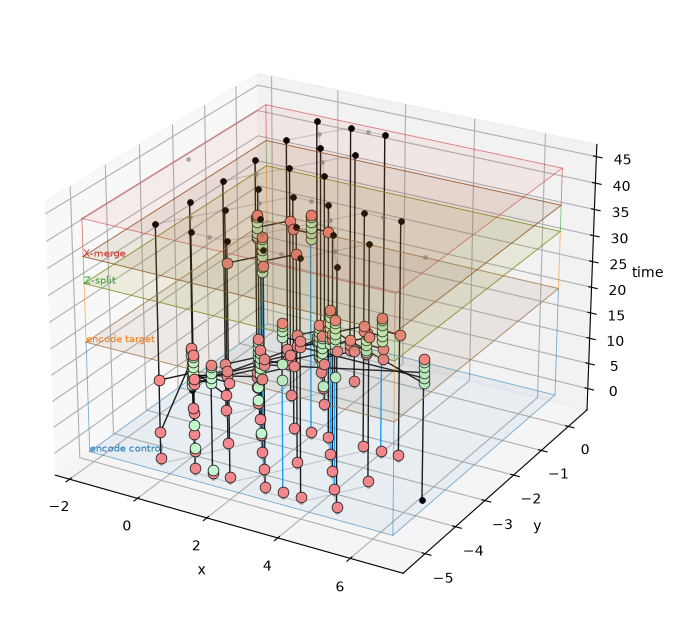

In [11]:
draw_program_3d(program, level=level1, figsize=(10, 8), show_phases=False)

## Summary

* The tool reads every code of a lattice-surgery CNOT off its gates: the 6×3 control, the 3×3 target, the two halves after the split, and the merged 3×6 patch.
* Read as one code, the split control still holds one logical qubit ($Z_L \otimes Z_L$ is a stabilizer), so the split does nothing and the merge does the CNOT. Read as separate patches (`separated`), the split is a Z-split and the merge a measurement of $XX$: Kissinger's logical description, found from the gates.
* Levelled up, split and merge together are a CNOT, in every run up to a Pauli frame; the frame, $Z$ on the control or the target depending on parities of the outcomes, is the byproduct of lattice surgery.

What is not covered: one round of checks per step, without noise; a fault-tolerant surgery measures every check $d$ times, and its circuit distance is not computed here.